<a href="https://colab.research.google.com/github/onumaechimargaret-wq/My-Project-work-gas-adsorption-modelling-python/blob/Equilibrium-theory/Equilibrium_Theory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Romulus breakthrough time (s): 734.558
Remus breakthrough time (s): 225.376
Romulus fraction of bed used: 0.846 unused bed length (m): 0.049
Remus fraction of bed used: 0.752 unused bed length (m): 0.079


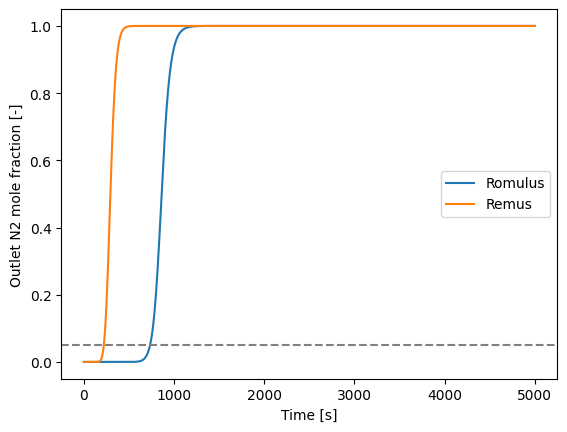

In [1]:
#-----------------------------------------------------------
# a: This part is done by Abhishna
#---------------------------------------------------------------
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#inputs
column_void_fraction = 0.32
density = 990 #kg/m3
particle_radius = 0.001 #m
tortuosity = 3
molecular_diffusivity = 7.481E-5 #m2/s
R = 8.314 # m3 Pa/molK
y_feed = 1.0 #N2 molefraction in the feed
k = 15*molecular_diffusivity/(tortuosity*(particle_radius**2))


#operating conditions:
T = 303 #Kelvin
P = 100000 #Pa
velocity = 4.864E-3 #m/s superficial velocity
v = velocity/column_void_fraction #m/s interstitial velocity

#grid definition
column_start = 0.0 #m
column_end = 0.32 #m

#divide the column into discrete lengths
grid_spacing = 0.005 #m
length_array = np.arange(column_start, column_end + grid_spacing, grid_spacing)
n = length_array.size

#isotherm equation

def q_star_Romulus(p_O2, p_N2):
    q_max_N2 = 2.5419      # mol/kg
    q_max_O2 = 4.705       #mol/kg
    b_N2 = 4.35e-6       # 1/Pa
    b_O2 = 3.414e-7       # 1/Pa

    return q_max_N2 * b_N2* p_N2 / (1 + (b_N2 * p_N2) + (b_O2 * p_O2)), q_max_O2 * b_O2* p_O2 / (1 + (b_N2 * p_N2) + (b_O2 * p_O2))

def q_star_Remus(p_O2, p_N2):
    q_max_N2 = 2.8344      # mol/kg
    q_max_O2 = 6.0977       #mol/kg
    b_N2 = 9.80e-7       # 1/Pa
    b_O2 = 1.69e-7       # 1/Pa

    return q_max_N2 * b_N2* p_N2 / (1 + (b_N2 * p_N2) + (b_O2 * p_O2)), q_max_O2 * b_O2* p_O2 / (1 + (b_N2 * p_N2) + (b_O2 * p_O2))

isotherms = {
    "Romulus": q_star_Romulus,
    "Remus": q_star_Remus,
}

def ode_system(
    t,
    y,
    k,
    y_feed,
    R: float,
    T: float,
    P: float,
    density: float,
    column_void_fraction: float,
    v: float,
    length_array: np.ndarray,
    grid_spacing: float,
    isotherm
):

    n = length_array.size
    y_N2 = y[:n].copy()
    q_N2 = y[n:2*n]
    q_O2 = y[2*n:]

    D_L = (0.7*molecular_diffusivity) + (velocity*particle_radius)
#boundary condition
#inlet
    a = D_L / (v * grid_spacing)
    y_N2[0] = (y_feed + a * y_N2[1]) / (1 + a)
#outlet
    y_N2[-1]=y_N2[-2]

#solid phase mass balance
    p_N2 = P * y_N2
    p_O2 = P * (1 - y_N2)
    q_star_N2,q_star_O2 = isotherm(p_O2, p_N2)
    dq_N2dt = k * (q_star_N2 - q_N2)
    dq_O2dt = k * (q_star_O2 - q_O2)


#component mass balance

    d2y_dz2 = np.zeros_like(y_N2)
    d2y_dz2[1:-1] = (y_N2[2:] - 2*y_N2[1:-1] + y_N2[:-2]) / grid_spacing**2
    dy_dz = np.zeros_like(y_N2)
    dy_dz[1:] = (y_N2[1:] - y_N2[:-1]) / grid_spacing


    #Substituting in component mass balance equation
    dy_N2dt=(D_L * d2y_dz2)- (v*dy_dz)-((R*T/P)*(density*(1-column_void_fraction)/ column_void_fraction)*dq_N2dt)
    dy_N2dt[0] = 0
    dy_N2dt[-1] = dy_N2dt[-2]



    return np.concatenate([dy_N2dt, dq_N2dt, dq_O2dt])

results = {}

for name, isotherm in isotherms.items():
    q_O2_init = isotherm(P, 0.0)[1]            # pure O2 at 100 kPa
    state0 = np.concatenate([np.zeros(n),
                             np.zeros(n),
                             np.full(n, q_O2_init)])
    sol = solve_ivp(ode_system, t_span=(0, 5000),
                    y0=state0,
                    method="BDF",
                    t_eval=np.linspace(0, 5000, 600), rtol=1e-6, atol=1e-9,
                    args=(k, y_feed, R, T, P, density, column_void_fraction,
                          v, length_array, grid_spacing, isotherm))
    outlet = sol.y[n-1]
    t_bt = sol.t[np.argmax(outlet >= 0.05)]  #breakthrough time
    results[name] = (sol.t, outlet, t_bt)
    print(name, "breakthrough time (s):", round(t_bt,3))

def fraction_bed_used(t,outlet, y_feed ,t_bt):
    integrand = 1 - outlet/y_feed
    sat = outlet >= 0.99 * y_feed      # bed saturation
    if not sat.any():
      return np.nan
    t_s = t[np.argmax(sat)]       #saturation time
    N2_bt = np.trapezoid(integrand[t <= t_bt],t[t <= t_bt])
    N2_s = np.trapezoid(integrand[t <= t_s],t[t <= t_s])

    return N2_bt/N2_s

for name, (t,outlet,t_bt) in results.items():
    f = fraction_bed_used(t,outlet,y_feed, t_bt)
    L_LUB = column_end*(1-f)
    print(name, "fraction of bed used:", round(f,3),
        "unused bed length (m):", round(L_LUB,3))

for name, (t, outlet, t_bt) in results.items():
    plt.plot(t, outlet, label=name)

plt.axhline(0.05, linestyle="--", color="grey")
plt.xlabel("Time [s]")
plt.ylabel("Outlet N2 mole fraction [-]")
plt.legend()
plt.show()

Romulus Equilibrium Theory Shock Time: 880.76 s
Remus Equilibrium Theory Shock Time: 303.31 s


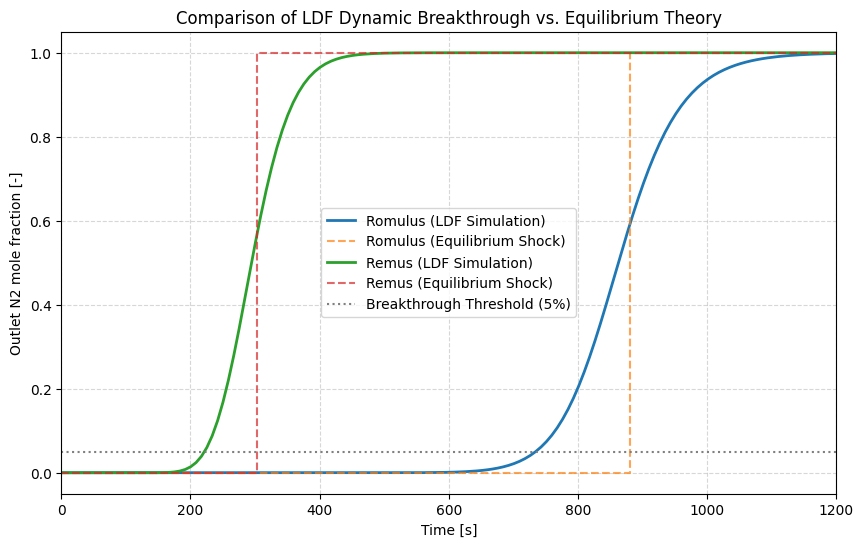

Romulus:
  breakthrough time (y_N2 = 0.05)  :    734.6 s
  stoichiometric time (equilibrium shock) :    880.8 s
  bed utilisation                     :    84.55 %
  length of unused bed (LUB)          :   0.0494 m

Remus:
  breakthrough time (y_N2 = 0.05)  :    225.4 s
  stoichiometric time (equilibrium shock) :    303.3 s
  bed utilisation                     :    75.21 %
  length of unused bed (LUB)          :   0.0793 m



In [3]:
#----------------------------------------------------------
# b: This is done by Obiageli Onumaechi
#---------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# Total gas phase concentration (mol/m3)
c_total = P / (R * T)

# Calculate equilibrium theory breakthrough times
eq_times = {}
for name, isotherm in isotherms.items():
    # Under feed conditions (y_N2 = 1.0, p_N2 = P, p_O2 = 0)
    q_N2_feed, _ = isotherm(0.0, P)

    # Solid-to-gas capacity ratio (dimensionless group phi)
    phi = ((1 - column_void_fraction) / column_void_fraction) * density * (q_N2_feed / c_total)

    # Shock velocity (m/s)
    w = v / (1 + phi)

    # Stoichiometric / shock breakthrough time (s)
    t_shock = column_end / w
    eq_times[name] = t_shock
    print(f"{name} Equilibrium Theory Shock Time: {round(t_shock, 2)} s")

# Plot the comparison
plt.figure(figsize=(10, 6))
for name, (t, outlet, t_bt) in results.items():
    # Plot simulated breakthrough curve
    plt.plot(t, outlet, label=f"{name} (LDF Simulation)", lw=2)
    # Plot corresponding equilibrium theory shock front step change
    t_eq = eq_times[name]
    plt.plot([0, t_eq, t_eq, max(t)], [0, 0, 1.0, 1.0], '--', label=f"{name} (Equilibrium Shock)", alpha=0.7)

plt.axhline(0.05, linestyle=":", color="grey", label="Breakthrough Threshold (5%)")
plt.xlabel("Time [s]")
plt.ylabel("Outlet N2 mole fraction [-]")
plt.title("Comparison of LDF Dynamic Breakthrough vs. Equilibrium Theory")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(0, 1200)
plt.show()

# Access and print the bed utilization and length of unused bed (LUB) for each adsorbent from the simulation results
breakthrough_y = 0.05
for name, (t, outlet, t_bt) in results.items():
    # Calculate fraction of bed used using the loaded function
    bed_utilisation = fraction_bed_used(t, outlet, y_feed, t_bt)
    LUB = column_end * (1.0 - bed_utilisation)

    print(f"{name}:")
    print(f"  breakthrough time (y_N2 = {breakthrough_y})  : {t_bt:8.1f} s")
    print(f"  stoichiometric time (equilibrium shock) : {eq_times[name]:8.1f} s")
    print(f"  bed utilisation                     : {100 * bed_utilisation:8.2f} %")
    print(f"  length of unused bed (LUB)          : {LUB:8.4f} m\n")